# Phase 2: Morphological Processing & Organ Segmentation

**Goal:** isolate the liver and the focal lesions from the surrounding anatomy, compare two classical strategies, and validate the masks against the radiologist annotation.

| Task | What is done here |
|---|---|
| 1 | Custom structuring elements and the four morphological operations (erosion, dilation, opening, closing) |
| 2 | **Strategy A**: Multi-Otsu thresholding. **Strategy B**: marker-controlled watershed. Lesion detection inside the liver |
| 3 | Dice and IoU against ground truth on the training and the held-out test patients |

Colour convention for every overlay: **red = predicted contour, green = ground-truth contour**.
Code lives in `../source/segmentation.py` and `../source/metrics.py`.

In [1]:
import sys, os
sys.path.append("../source")          # the modules live in ../source
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import utilities as util
import enhancement as enh

import segmentation as S
import metrics as M
from skimage.measure import label, regionprops
from scipy import stats
RED, GREEN, YELLOW = (255, 0, 0), (0, 255, 0), (255, 255, 0)

DATA_DIR = "../data/slices"           # extracted .npz slices (patient_<N>.npz)
FIG_DIR = "../figures"                # figures for the report are saved here
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams["figure.dpi"] = 90
plt.rcParams["figure.max_open_warning"] = 0

In [2]:
def contour_overlay(gray, layers, thickness=1):
    """RGB copy of a gray image with the contour of every (mask, colour) pair drawn on it."""
    rgb = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
    for m, col in layers:
        cs, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, cs, -1, col, thickness)
    return rgb

def crop_to_body(img, body, margin=8):
    ys, xs = np.where(body)
    return img[max(ys.min() - margin, 0):ys.max() + margin, max(xs.min() - margin, 0):xs.max() + margin]

train_p, test_p = util.split_patients(util.list_patients(DATA_DIR))
print("training patients:", train_p)
print("test patients    :", test_p)

training patients: [0, 1, 2, 3, 4, 6, 8, 10, 11, 12, 13, 14, 15, 16, 18, 19, 20, 21, 24, 28, 29]
test patients    : [5, 7, 17, 22, 23, 25, 26, 27, 30]


## Task 1: Morphological operations with custom structuring elements

A **structuring element (SE)** is the small probe that is slid over a binary mask. Its shape decides what is removed or kept.

* **Erosion** keeps a pixel only if the whole SE fits inside the mask (shrinks, cuts thin links).
* **Dilation** sets a pixel if the SE touches the mask (grows, bridges small gaps).
* **Opening** = erosion then dilation: disconnects touching organs and removes specks.
* **Closing** = dilation then erosion: fills small holes while keeping the outline.

Five SEs are defined in `segmentation.py`: disk, ellipse (different horizontal/vertical radius), cross and line (any angle).

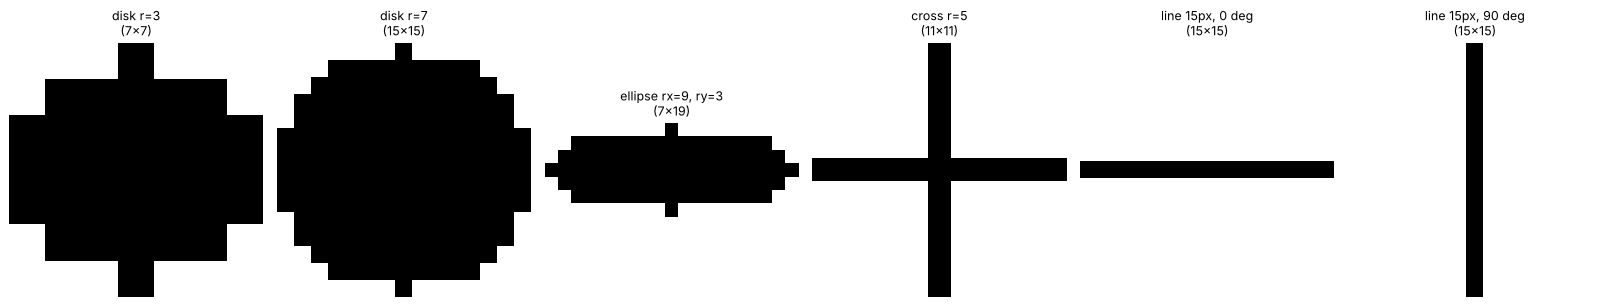

In [3]:
ses = {"disk r=3": S.disk_se(3), "disk r=7": S.disk_se(7), "ellipse rx=9, ry=3": S.ellipse_se(9, 3),
       "cross r=5": S.cross_se(5), "line 15px, 0 deg": S.line_se(15, 0), "line 15px, 90 deg": S.line_se(15, 90)}
fig, ax = plt.subplots(1, len(ses), figsize=(18, 3.4))
for a, (n, se) in zip(ax, ses.items()):
    a.imshow(se, cmap="gray_r", vmin=0, vmax=1); a.set_title(n + "\n(%dx%d)" % se.shape, fontsize=10); a.axis("off")
fig.tight_layout(); fig.savefig(FIG_DIR + "/p2_structuring_elements.png", dpi=100); plt.show()

### Intermediate steps of Strategy A and B on one slice

To show the operations on *real* data, the notebook re-runs the individual steps of the two strategies (these helper functions only expose the intermediate images; the result is checked against the real functions in `segmentation.py`).

In [4]:
def strategy_a_steps(gray, body, classes=4, open_r=5, close_r=9):
    """Strategy A with every intermediate image kept (mirrors S.strategy_a_organ)."""
    bbox = S.body_bbox(body)
    th = S.multiotsu_thresholds(gray, body, classes)
    labels = np.digitize(gray, th)
    best, best_score = None, 0.0
    for k in range(1, classes):
        raw = (labels == k) & body
        opened = S.opening(raw, S.disk_se(open_r))
        comp, score = S.select_liver_component(opened, bbox)
        if comp.any() and not (S.LIVER_GRAY_RANGE[0] <= np.median(gray[comp]) <= S.LIVER_GRAY_RANGE[1]):
            continue
        if score > best_score:
            best, best_score = dict(k=k, raw=raw, opened=opened, comp=comp), score
    if best is None:
        return None
    best["th"], best["labels"] = th, labels
    best["closed"] = S.fill_holes(S.closing(best["comp"], S.disk_se(close_r)))
    final = S.opening(best["closed"], S.disk_se(3))
    best["final"], _ = S.select_liver_component(final, bbox)
    return best

def strategy_b_steps(gray, body, tol=28, fg_erode=8, bg_dilate=15):
    """Strategy B with every intermediate image kept (mirrors S.strategy_b_organ)."""
    bbox = S.body_bbox(body)
    sy, sx = S.prior_seed(bbox)
    win = np.zeros(gray.shape, bool); win[max(sy - 15, 0):sy + 16, max(sx - 15, 0):sx + 16] = True
    sample = gray[win & body]; sample = sample[(sample >= S.LIVER_GRAY_RANGE[0]) & (sample <= S.LIVER_GRAY_RANGE[1])]
    ref = np.median(sample)
    band = S.opening(body & (np.abs(gray.astype(np.int16) - ref) <= tol), S.disk_se(3))
    coarse, _ = S.select_liver_component(band, bbox)
    fg = S.erode(coarse, S.disk_se(fg_erode))
    bg = ~S.dilate(coarse, S.disk_se(bg_dilate)) | ~body
    markers = np.zeros(gray.shape, np.int32); markers[bg] = 1; markers[fg] = 2
    grad = S.sobel(gray.astype(np.float64) / 255.0)
    ws = S.watershed(grad, markers) == 2
    ws2 = S.fill_holes(S.closing(ws, S.disk_se(7)))
    ws2 = S.opening(ws2, S.disk_se(3))
    final, _ = S.select_liver_component(ws2, bbox)
    return dict(seed=(sy, sx), ref=ref, band=band, coarse=coarse, fg=fg, bg=bg, grad=grad, ws=ws, final=final)

# example slice for the step-by-step figures
PID, POS = 3, 4
hu_all, mask_all, idx = util.load_patient(DATA_DIR, PID)
hu, mask = hu_all[POS], mask_all[POS]
gt_liver, gt_tumor = mask >= 1, mask == 2
gray = S.smooth_for_segmentation(util.hu_to_gray(hu))          # window L50/W350 + bilateral (Phase 1)
body = enh.body_mask(hu)

A = strategy_a_steps(gray, body)
B = strategy_b_steps(gray, body)
# consistency check against the real implementation
print("Strategy A steps identical to S.strategy_a_organ:", np.array_equal(A["final"], S.strategy_a_organ(gray, body)[0]))
print("Strategy B steps identical to S.strategy_b_organ:", np.array_equal(B["final"], S.strategy_b_organ(gray, body)[0]))

Strategy A steps identical to S.strategy_a_organ: True
Strategy B steps identical to S.strategy_b_organ: True


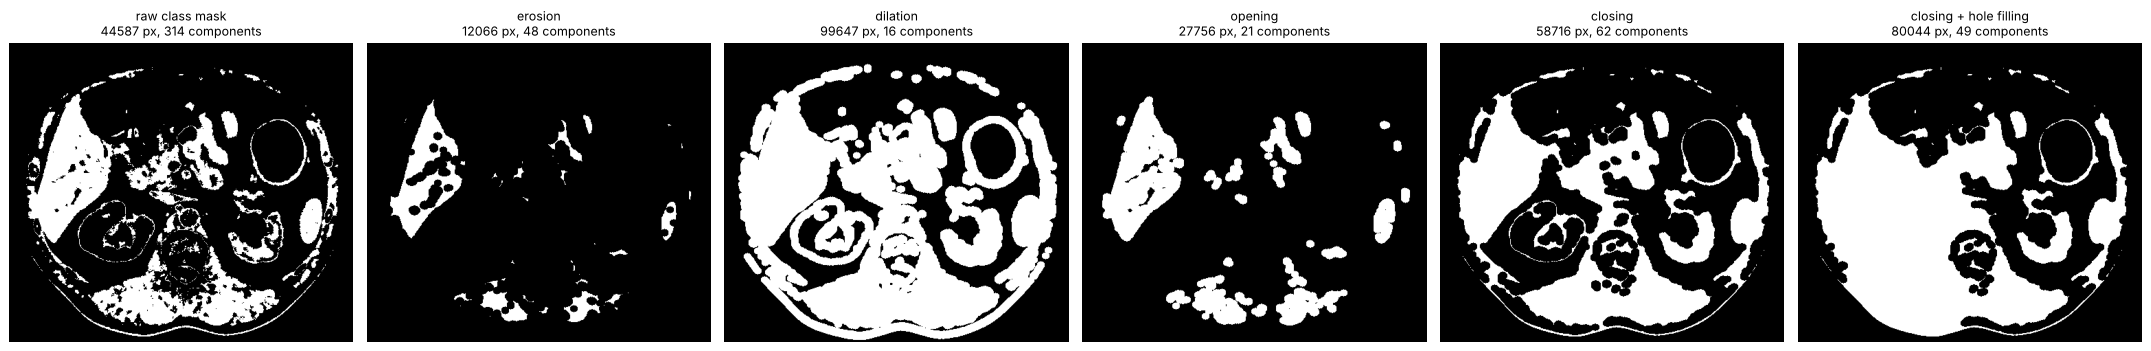

In [5]:
# The four operations on the raw Multi-Otsu liver-class mask, with a disk SE
raw = A["raw"]
se = S.disk_se(5)
ops = {"raw class mask": raw, "erosion": S.erode(raw, se), "dilation": S.dilate(raw, se),
       "opening": S.opening(raw, se), "closing": S.closing(raw, se), "closing + hole filling": S.fill_holes(S.closing(raw, se))}
fig, ax = plt.subplots(1, 6, figsize=(24, 4.5))
for a, (n, m) in zip(ax, ops.items()):
    a.imshow(crop_to_body(m, body), cmap="gray"); a.set_title("%s\n%d px, %d components" % (n, m.sum(), label(m).max()), fontsize=10); a.axis("off")
fig.tight_layout(); fig.savefig(FIG_DIR + "/p2_morphology_ops.png", dpi=100); plt.show()

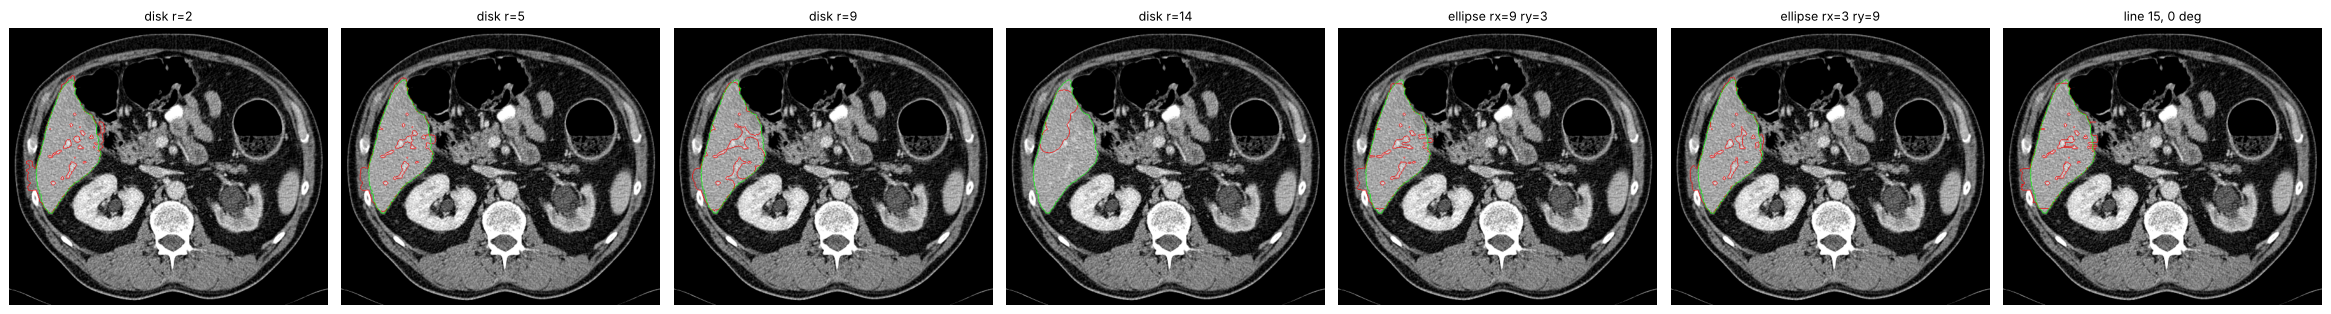

,opening SE,pixels kept,components,selected liver px,Dice vs GT
0,disk r=2,37351,76,13016,0.935
1,disk r=5,27756,21,12477,0.940
2,disk r=9,17871,8,11419,0.914
3,disk r=14,9032,4,3485,0.439
4,ellipse rx=9 ry=3,24808,21,12223,0.936
5,ellipse rx=3 ry=9,25401,22,12459,0.942
6,"line 15, 0 deg",29394,54,12530,0.940


In [6]:
# Effect of the SE shape/size on the opening that separates the liver from touching organs
tests = {"disk r=2": S.disk_se(2), "disk r=5": S.disk_se(5), "disk r=9": S.disk_se(9), "disk r=14": S.disk_se(14),
         "ellipse rx=9 ry=3": S.ellipse_se(9, 3), "ellipse rx=3 ry=9": S.ellipse_se(3, 9), "line 15, 0 deg": S.line_se(15, 0)}
rows = []
fig, ax = plt.subplots(1, len(tests), figsize=(26, 4.2))
for a, (n, se_) in zip(ax, tests.items()):
    o = S.opening(raw, se_)
    comp, _ = S.select_liver_component(o, S.body_bbox(body))
    rows.append((n, int(o.sum()), label(o).max(), int(comp.sum()), M.dice_score(comp, gt_liver)))
    a.imshow(contour_overlay(crop_to_body(util.hu_to_gray(hu), body), [(crop_to_body(comp, body), RED), (crop_to_body(gt_liver, body), GREEN)])); a.set_title(n, fontsize=10); a.axis("off")
fig.tight_layout(); fig.savefig(FIG_DIR + "/p2_se_comparison.png", dpi=100); plt.show()
pd.DataFrame(rows, columns=["opening SE", "pixels kept", "components", "selected liver px", "Dice vs GT"]).round(3)

**Findings (structuring elements).** On this slice, opening the raw class mask with a small disk (r = 2) leaves 76 separate fragments, so the liver is still attached to noise and neighbouring tissue; r = 5 reduces this to 21 components and gives the best disk result (Dice 0.940). Larger elements remove more clutter (r = 9 leaves 8 components) but start to eat the narrow parts of the liver (Dice 0.914), and r = 14 destroys it (Dice 0.439, 3485 px kept). The orientation of the SE matters little here: the elongated ellipses (Dice 0.936 and 0.942) and the line SE (0.940) are all close to the disk. A disk with r = 5 is the compromise used in the pipeline; the SE must be smaller than the narrowest liver part that has to survive.

## Task 2, Strategy A: Multi-Otsu thresholding

Otsu's method chooses the threshold that maximises the **between-class variance** of the histogram; Multi-Otsu extends this to several thresholds. Here the histogram of the **body pixels** (air outside the body would otherwise dominate) is split into 4 classes (fat / low soft tissue / liver-spleen / bright). Each non-darkest class is cleaned with an opening (disk r = 5), the component with the best *area x spatial-prior* score is chosen, and a closing (r = 9), hole filling and a small opening (r = 3) recover the boundary and the lesions that were left as holes.

The spatial prior is a Gaussian around the mean liver position measured on the **training** patients (about 27 % from the left and 43 % from the top of the body box).

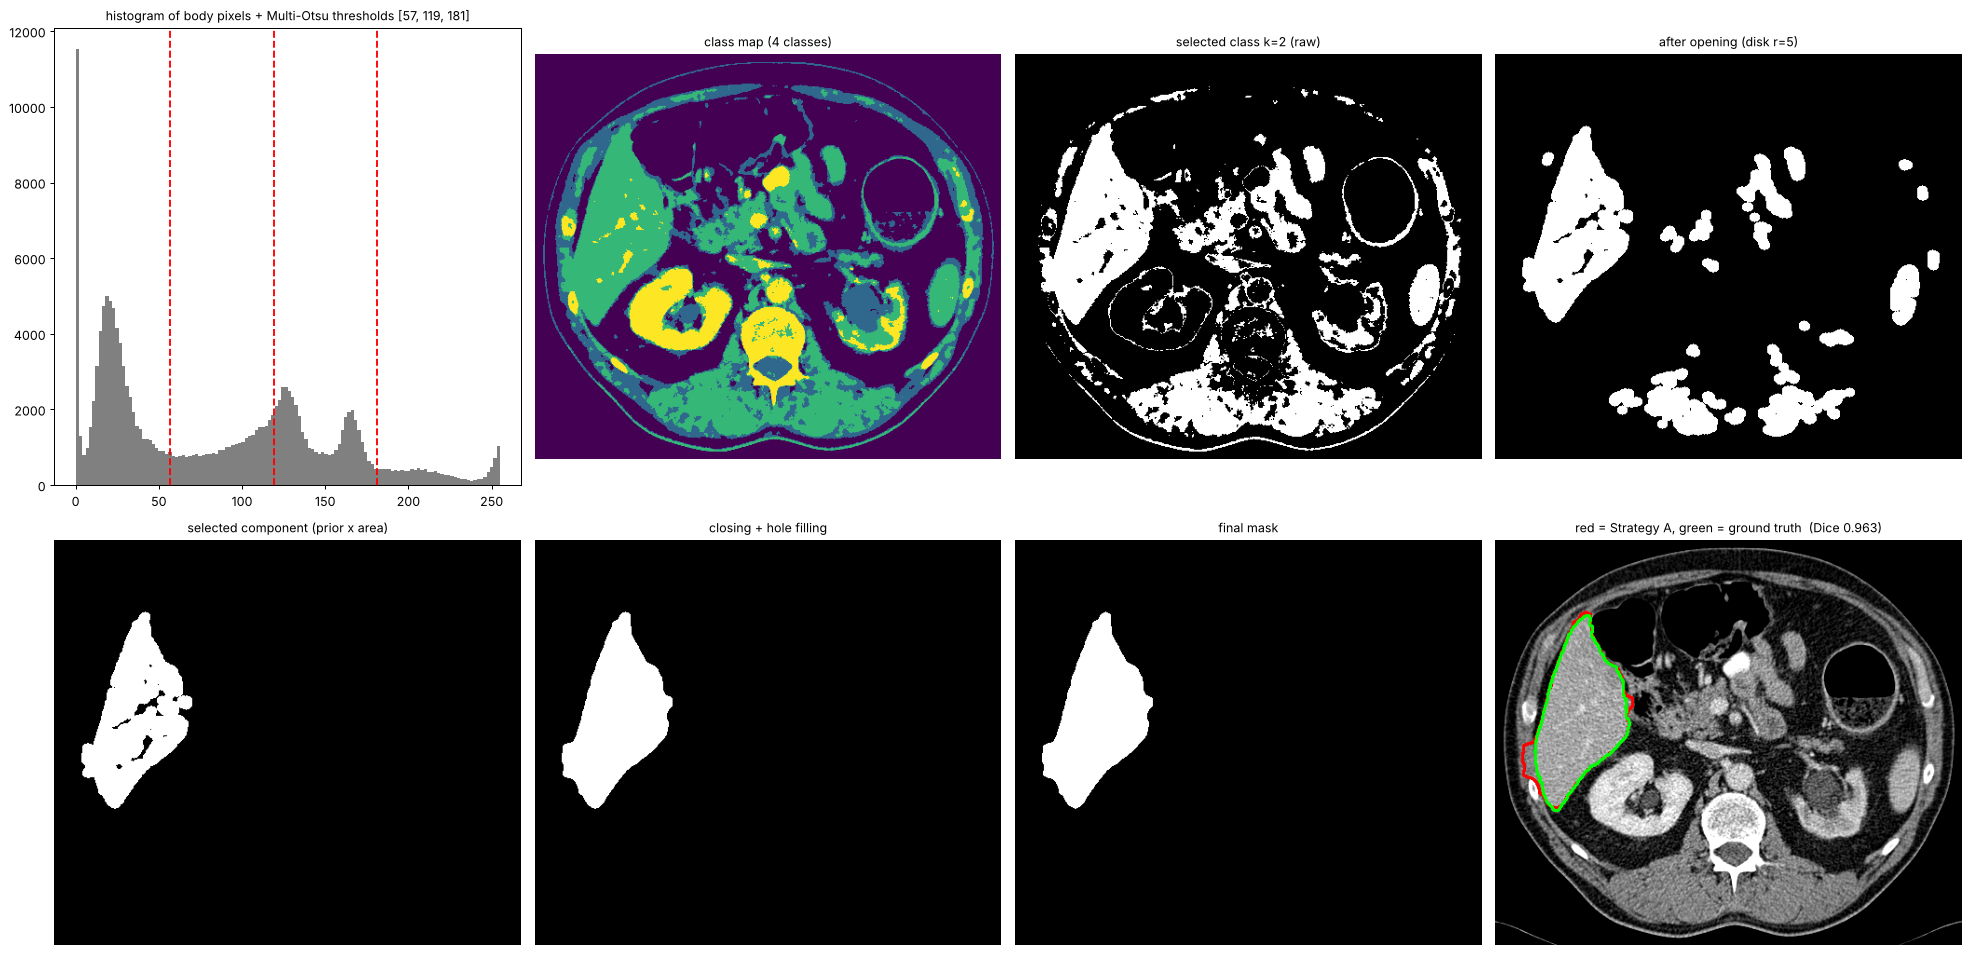

In [7]:
fig, ax = plt.subplots(2, 4, figsize=(22, 11))
ax[0, 0].hist(gray[body].ravel(), 128, range=(0, 255), color="gray")
for t in A["th"]: ax[0, 0].axvline(t, color="red", ls="--")
ax[0, 0].set_title("histogram of body pixels + Multi-Otsu thresholds %s" % np.round(A["th"], 0).tolist(), fontsize=10)
panels = [("class map (4 classes)", crop_to_body(A["labels"] * body, body), "viridis"),
          ("selected class k=%d (raw)" % A["k"], crop_to_body(A["raw"], body), "gray"),
          ("after opening (disk r=5)", crop_to_body(A["opened"], body), "gray"),
          ("selected component (prior x area)", crop_to_body(A["comp"], body), "gray"),
          ("closing + hole filling", crop_to_body(A["closed"], body), "gray"),
          ("final mask", crop_to_body(A["final"], body), "gray")]
for a, (t, im, cm) in zip(list(ax.ravel())[1:], panels):
    a.imshow(im, cmap=cm); a.set_title(t, fontsize=10); a.axis("off")
a = ax.ravel()[7]
a.imshow(contour_overlay(crop_to_body(util.hu_to_gray(hu), body), [(crop_to_body(A["final"], body), RED), (crop_to_body(gt_liver, body), GREEN)], 2))
a.set_title("red = Strategy A, green = ground truth  (Dice %.3f)" % M.dice_score(A["final"], gt_liver), fontsize=10); a.axis("off")
ax[0, 0].axis("on")
fig.tight_layout(); fig.savefig(FIG_DIR + "/p2_strategyA_steps.png", dpi=90); plt.show()

## Task 2, Strategy B: Marker-controlled watershed

The gradient magnitude (Sobel) of the smoothed image is treated as a topographic surface: edges are ridges, homogeneous tissue is a basin. **Markers** are flooded simultaneously and the regions meet at the strongest edges.

* **Seed:** the expected liver centroid from the spatial prior. The liver intensity is estimated from the liver-like pixels around it, and the coarse region is all pixels within +-28 gray levels, cleaned and spatially selected.
* **Foreground marker:** the coarse region eroded by a disk (r = 8): certainly liver.
* **Background marker:** everything outside the body or farther than 15 px from the coarse region: certainly not liver.
* The watershed result is closed, hole-filled and opened like Strategy A.

Strategy B does not use the Multi-Otsu result: only the spatial prior and the local intensity.

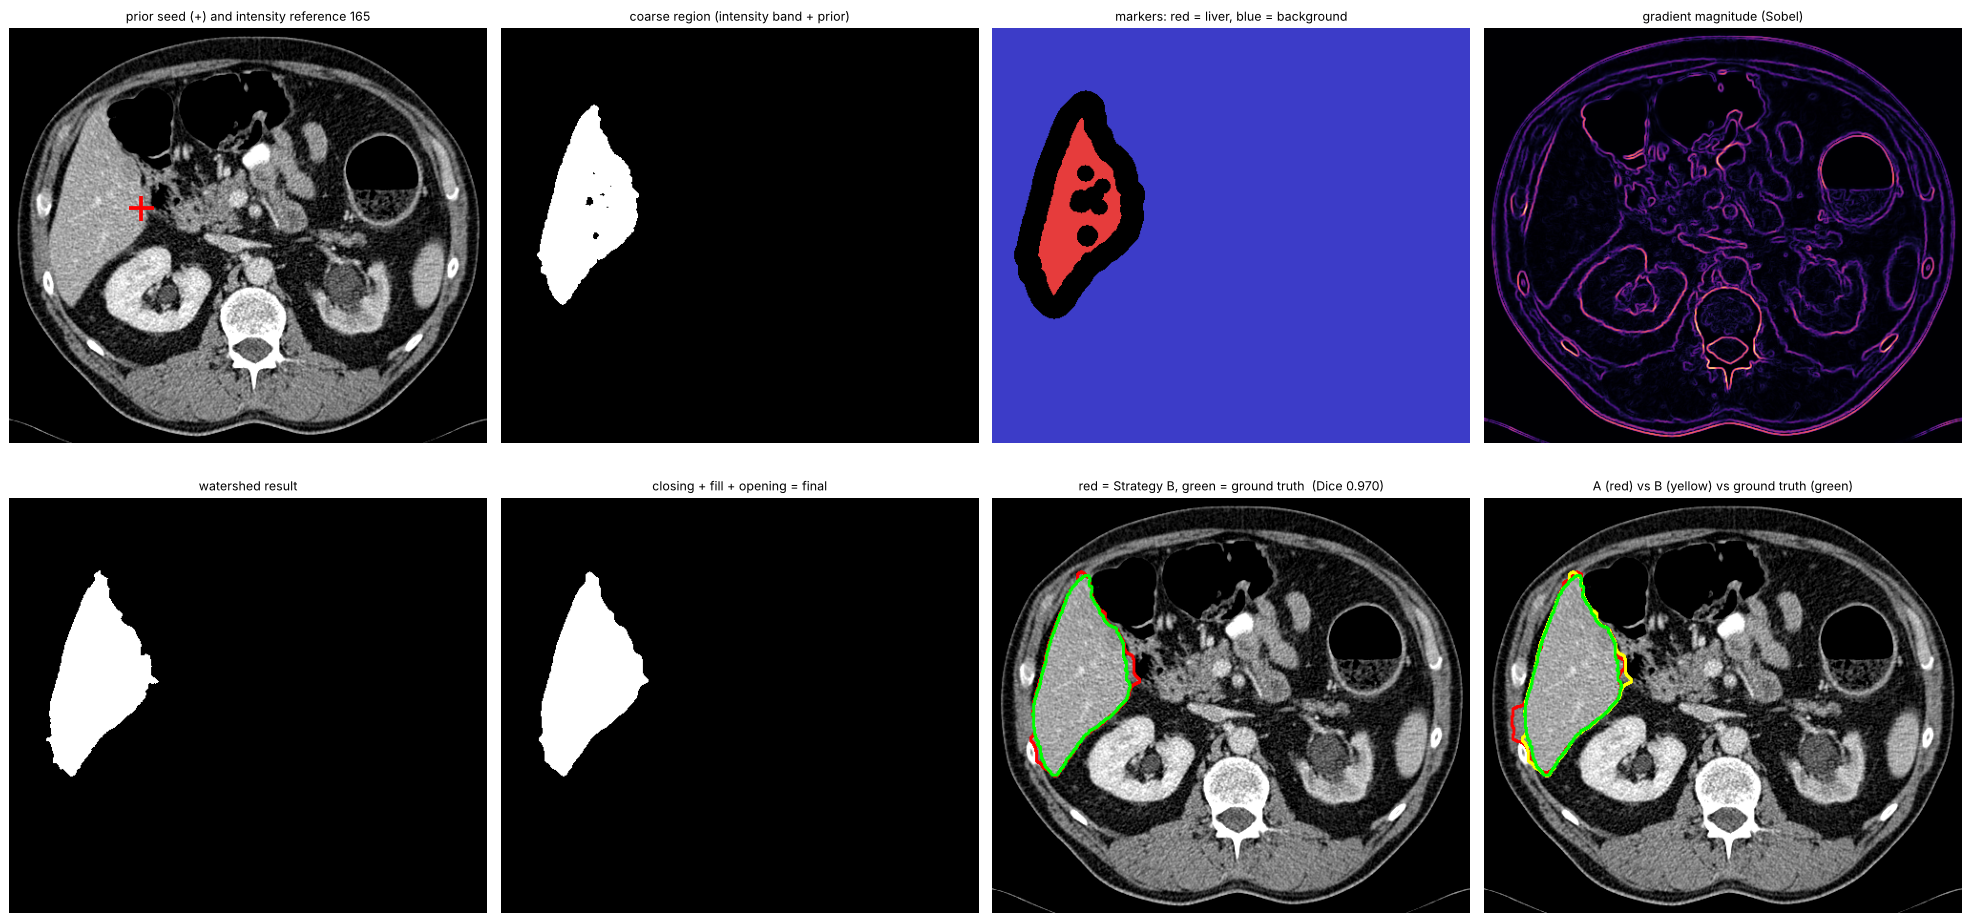

In [8]:
fig, ax = plt.subplots(2, 4, figsize=(22, 11))
g_crop = lambda m: crop_to_body(m, body)
base = util.hu_to_gray(hu)
sy, sx = B["seed"]
a = ax[0, 0]; a.imshow(g_crop(base), cmap="gray"); a.set_title("prior seed (+) and intensity reference %.0f" % B["ref"], fontsize=10)
ys, xs = np.where(body); a.plot(sx - max(xs.min() - 8, 0), sy - max(ys.min() - 8, 0), "r+", ms=20, mew=3); a.axis("off")
mk = np.zeros(gray.shape + (3,), np.uint8); mk[B["bg"]] = (60, 60, 200); mk[B["fg"]] = (230, 60, 60)
panels = [("coarse region (intensity band + prior)", g_crop(B["coarse"]), "gray"),
          ("markers: red = liver, blue = background", g_crop(mk), None),
          ("gradient magnitude (Sobel)", g_crop(B["grad"]), "magma"),
          ("watershed result", g_crop(B["ws"]), "gray"),
          ("closing + fill + opening = final", g_crop(B["final"]), "gray")]
for a, (t, im, cm) in zip(list(ax.ravel())[1:6], panels):
    a.imshow(im, cmap=cm) if cm else a.imshow(im); a.set_title(t, fontsize=10); a.axis("off")
a = ax.ravel()[6]
a.imshow(contour_overlay(g_crop(base), [(g_crop(B["final"]), RED), (g_crop(gt_liver), GREEN)], 2))
a.set_title("red = Strategy B, green = ground truth  (Dice %.3f)" % M.dice_score(B["final"], gt_liver), fontsize=10); a.axis("off")
a = ax.ravel()[7]
a.imshow(contour_overlay(g_crop(base), [(g_crop(A["final"]), RED), (g_crop(B["final"]), YELLOW), (g_crop(gt_liver), GREEN)], 2))
a.set_title("A (red) vs B (yellow) vs ground truth (green)", fontsize=10); a.axis("off")
fig.tight_layout(); fig.savefig(FIG_DIR + "/p2_strategyB_steps.png", dpi=90); plt.show()

## Lesion segmentation inside the liver

Tumors in LiTS are mostly **hypo-dense**: slightly darker than the liver. Inside the predicted liver mask:

1. smooth lightly (Gaussian, sigma 1.5) and **erode the mask** (disk r = 8) so the darker rim (partial volume, fat) is not mistaken for a lesion;
2. estimate the liver level robustly: median and MAD-based sigma of the interior;
3. mark pixels below `median - max(2 sigma, 10 gray levels)` but above a **floor** (gray 95: fat in fissures and the gallbladder are darker than any tumor);
4. opening (r = 2), closing (r = 3), drop blobs smaller than 60 px;
5. keep only **compact** blobs (solidity >= 0.8) so thin dark vessels are rejected.

liver median 166, robust sigma 4.4 -> threshold 156 | identical to S.segment_lesion: True


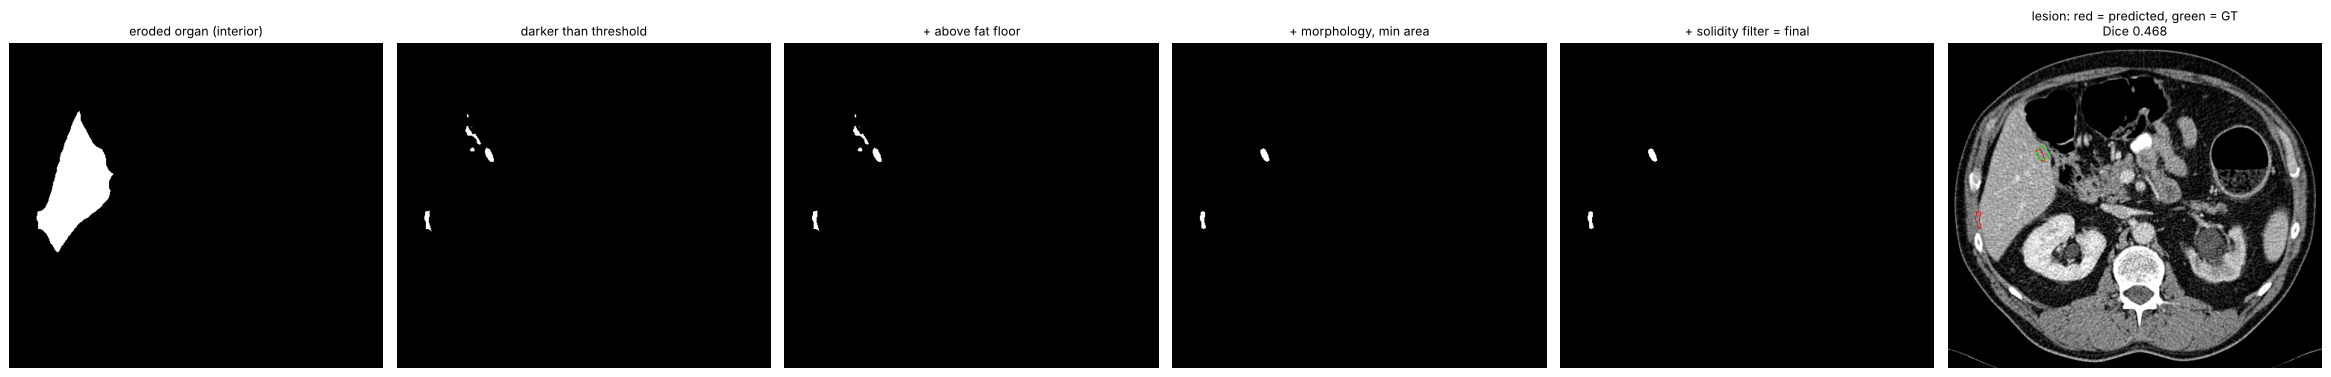

In [9]:
organ = A["final"]
smooth = cv2.GaussianBlur(gray, (0, 0), 1.5)
inner = S.erode(organ, S.disk_se(8))
vals = smooth[inner].astype(float); med = np.median(vals); sig = 1.4826 * np.median(np.abs(vals - med))
thr = med - max(2.0 * sig, 10)
cand0 = inner & (smooth < thr)
cand1 = cand0 & (smooth > 95)
cand2 = S.remove_small_components(S.closing(S.opening(cand1, S.disk_se(2)), S.disk_se(3)), 60)
lab = label(cand2); cand3 = np.zeros_like(cand2)
for r in regionprops(lab):
    if r.solidity >= 0.8: cand3[lab == r.label] = True
print("liver median %.0f, robust sigma %.1f -> threshold %.0f | identical to S.segment_lesion:" % (med, sig, thr), np.array_equal(cand3, S.segment_lesion(gray, organ)))

fig, ax = plt.subplots(1, 6, figsize=(26, 4.8))
steps = [("eroded organ (interior)", inner), ("darker than threshold", cand0), ("+ above fat floor", cand1), ("+ morphology, min area", cand2), ("+ solidity filter = final", cand3)]
for a, (t, m) in zip(ax, steps):
    a.imshow(crop_to_body(m, body), cmap="gray"); a.set_title(t, fontsize=10); a.axis("off")
ax[5].imshow(contour_overlay(crop_to_body(base, body), [(crop_to_body(cand3, body), RED), (crop_to_body(gt_tumor, body), GREEN)], 1))
ax[5].set_title("lesion: red = predicted, green = GT\nDice %.3f" % M.dice_score(cand3, gt_tumor), fontsize=10); ax[5].axis("off")
fig.tight_layout(); fig.savefig(FIG_DIR + "/p2_lesion_steps.png", dpi=100); plt.show()

## Task 3: Mask validation (Dice and IoU)

$$\mathrm{DSC} = \frac{2|A \cap B|}{|A| + |B|} \qquad \mathrm{IoU} = \frac{|A \cap B|}{|A \cup B|}$$

Both strategies are run on **every slice with at least 3000 liver pixels**. Parameters were tuned on the training patients only; the test patients were run once. For the lesion, the Dice is computed on tumor-bearing slices (>= 50 tumor pixels); a tumor slice counts as *detected* if the predicted lesion overlaps the ground truth, and a tumor-free slice with any predicted lesion is a *false alarm*.

In [10]:
def evaluate(pids, split):
    rows = []
    for pid, sl, hu_i, m_i in util.iter_slices(DATA_DIR, pids):
        gt_o, gt_l = m_i >= 1, m_i == 2
        if gt_o.sum() < 3000:
            continue
        has = bool(gt_l.sum() >= 50)
        for s in "AB":
            o = S.segment_slice(hu_i, s)
            rows.append(dict(split=split, patient=pid, slice=sl, strategy=s, liver_px=int(gt_o.sum()), has_tumor=has,
                             dice=M.dice_score(o["organ"], gt_o), iou=M.iou_score(o["organ"], gt_o),
                             les_dice=M.dice_score(o["lesion"], gt_l) if has else np.nan,
                             les_hit=bool((o["lesion"] & gt_l).any()) if has else np.nan,
                             les_alarm=bool(o["lesion"].any()) if not has else np.nan))
    return pd.DataFrame(rows)

res = pd.concat([evaluate(train_p, "train"), evaluate(test_p, "test")], ignore_index=True)
print(res.groupby(["split", "strategy"]).size().unstack())

strategy    A    B
split             
test       89   89
train     201  201


In [11]:
def summarise(g):
    t, n = g[g.has_tumor], g[~g.has_tumor]
    return pd.Series({
        "slices": len(g),
        "liver Dice": "%.3f ± %.3f" % (g.dice.mean(), g.dice.std()),
        "liver Dice (median)": round(g.dice.median(), 3),
        "liver IoU": "%.3f ± %.3f" % (g.iou.mean(), g.iou.std()),
        "lesion Dice (tumor slices)": "%.3f ± %.3f" % (t.les_dice.mean(), t.les_dice.std()),
        "tumor slices detected": "%.0f %%" % (100 * t.les_hit.astype(float).mean()),
        "tumor-free slices with false alarm": "%.0f %% (n=%d)" % (100 * n.les_alarm.astype(float).mean(), len(n)),
    })
summary = res.groupby(["split", "strategy"]).apply(summarise, include_groups=False)
summary.to_csv(FIG_DIR + "/p2_segmentation_table.csv")
summary

slices     liver Dice  liver Dice (median)      liver IoU  \
split strategy                                                              
test  A             89  0.897 ± 0.141                0.947  0.833 ± 0.167   
      B             89  0.789 ± 0.260                0.898  0.706 ± 0.263   
train A            201  0.872 ± 0.181                0.941  0.806 ± 0.209   
      B            201  0.792 ± 0.285                0.907  0.720 ± 0.279   

               lesion Dice (tumor slices) tumor slices detected  \
split strategy                                                    
test  A                     0.269 ± 0.357                  47 %   
      B                     0.199 ± 0.294                  42 %   
train A                     0.268 ± 0.315                  55 %   
      B                     0.253 ± 0.278                  58 %   

               tumor-free slices with false alarm  
split strategy                                     
test  A                               50 % (n=36)  
      B                               56 % (n=36)  
train A                               22 % (n=80)  
      B                               50 % (n=80)

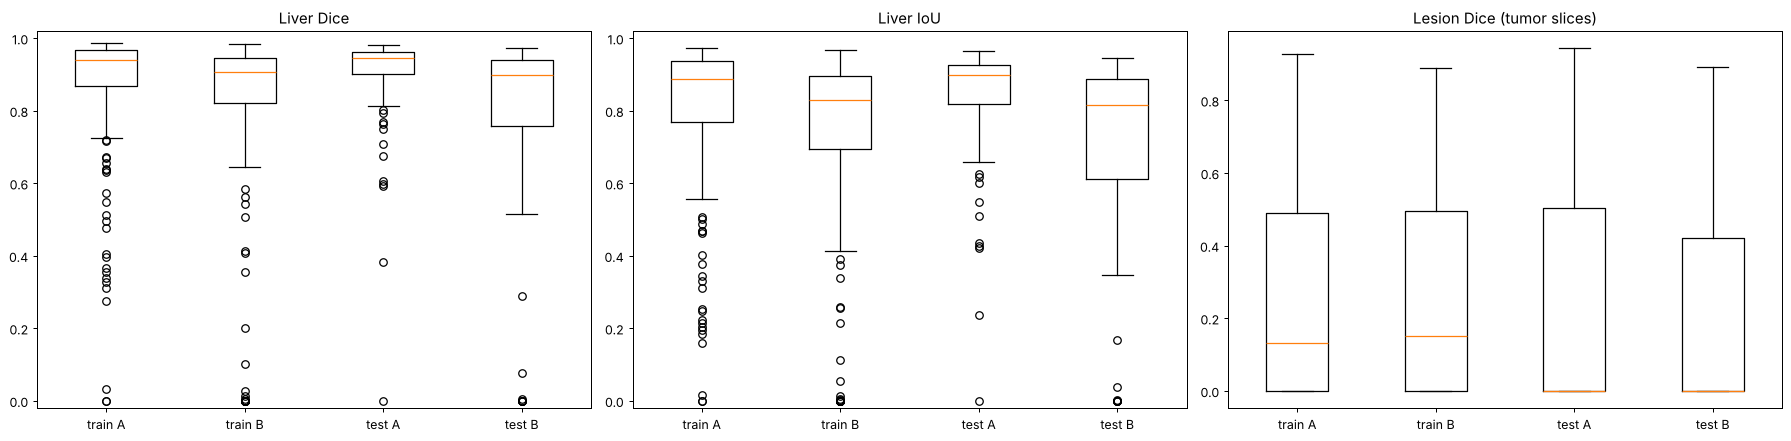

Test set, paired Wilcoxon signed-rank test A vs B on liver Dice: p = 5.3e-08  (A better on 82 % of slices)


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
for a, col, t in zip(ax[:2], ["dice", "iou"], ["Liver Dice", "Liver IoU"]):
    data = [res[(res.split == sp) & (res.strategy == st)][col] for sp in ("train", "test") for st in "AB"]
    a.boxplot(data, tick_labels=["train A", "train B", "test A", "test B"]); a.set_title(t); a.set_ylim(-0.02, 1.02)
t = res[res.has_tumor]
data = [t[(t.split == sp) & (t.strategy == st)].les_dice for sp in ("train", "test") for st in "AB"]
ax[2].boxplot(data, tick_labels=["train A", "train B", "test A", "test B"]); ax[2].set_title("Lesion Dice (tumor slices)")
fig.tight_layout(); fig.savefig(FIG_DIR + "/p2_dice_boxplots.png", dpi=100); plt.show()

# paired comparison of the strategies on the test patients
w = res[res.split == "test"].pivot_table(index=["patient", "slice"], columns="strategy", values="dice")
stat, p = stats.wilcoxon(w["A"], w["B"])
print("Test set, paired Wilcoxon signed-rank test A vs B on liver Dice: p = %.2g  (A better on %.0f %% of slices)" % (p, 100 * (w["A"] > w["B"]).mean()))

## Overlays: predicted (red) vs ground truth (green)

Six **test** slices, chosen automatically at fixed quantiles of the Strategy-A Dice (best to worst) so that both successes and failures are shown. Columns: the original slice, the predicted liver mask, the liver overlay for A and for B, the lesion overlay (A), and one combined view with liver and lesion contours together.

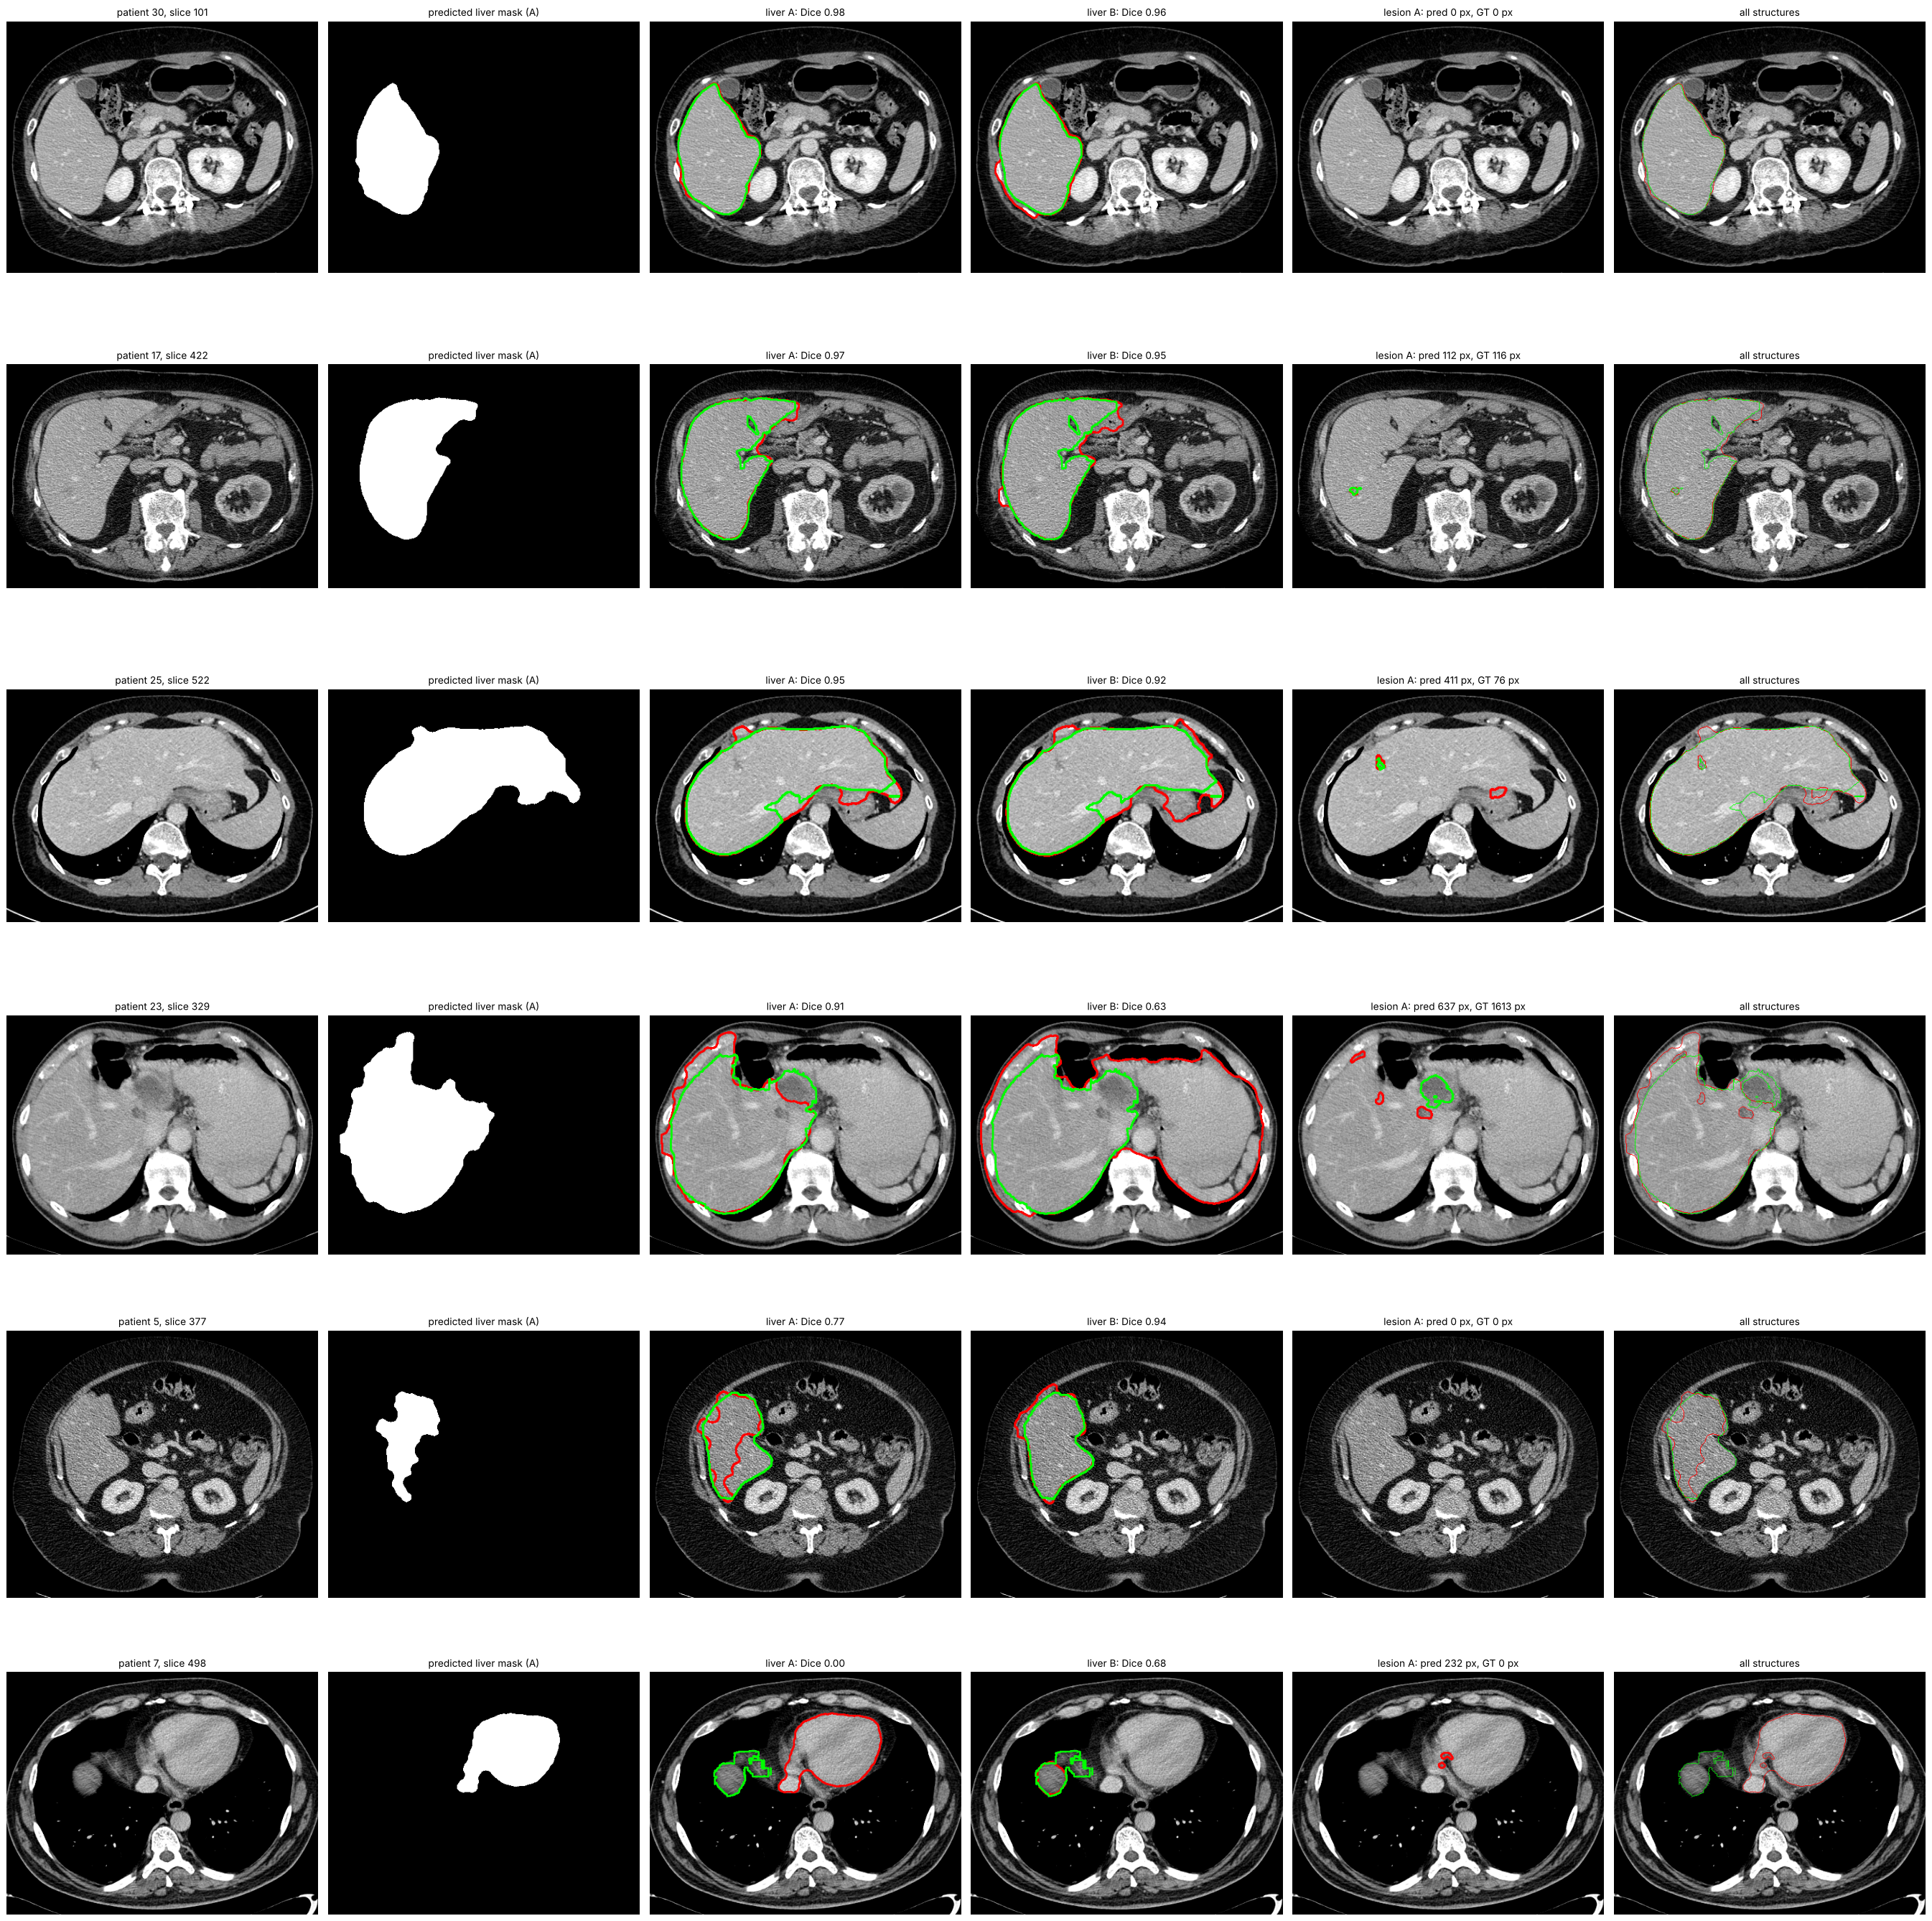

In [13]:
ta = res[(res.split == "test") & (res.strategy == "A")].sort_values("dice", ascending=False).reset_index(drop=True)
pick = [ta.iloc[int(q * (len(ta) - 1))] for q in (0.0, 0.2, 0.45, 0.7, 0.9, 1.0)]
fig, ax = plt.subplots(len(pick), 6, figsize=(30, 5.2 * len(pick)))
for r, row in enumerate(pick):
    hu_p, m_p, ix = util.load_patient(DATA_DIR, int(row.patient)); k = list(ix).index(int(row.slice))
    hu_i, m_i = hu_p[k], m_p[k]
    oa, ob = S.segment_slice(hu_i, "A"), S.segment_slice(hu_i, "B")
    g0 = util.hu_to_gray(hu_i); bd = oa["body"]
    cr = lambda x: crop_to_body(x, bd)
    gl, gt_l = m_i >= 1, m_i == 2
    cols = [cr(g0),
            cr(oa["organ"]),
            cr(contour_overlay(g0, [(oa["organ"], RED), (gl, GREEN)], 2)),
            cr(contour_overlay(g0, [(ob["organ"], RED), (gl, GREEN)], 2)),
            cr(contour_overlay(g0, [(oa["lesion"], RED), (gt_l, GREEN)], 2)),
            cr(contour_overlay(g0, [(oa["organ"], RED), (oa["lesion"], RED), (gl, GREEN), (gt_l, GREEN)], 1))]
    titles = ["patient %d, slice %d" % (row.patient, row.slice), "predicted liver mask (A)",
              "liver A: Dice %.2f" % M.dice_score(oa["organ"], gl), "liver B: Dice %.2f" % M.dice_score(ob["organ"], gl),
              "lesion A: pred %d px, GT %d px" % (oa["lesion"].sum(), gt_l.sum()), "all structures"]
    for c in range(6):
        ax[r, c].imshow(cols[c], cmap="gray" if cols[c].ndim == 2 else None); ax[r, c].set_title(titles[c], fontsize=11); ax[r, c].axis("off")
fig.tight_layout(); fig.savefig(FIG_DIR + "/p2_overlays_test.png", dpi=55); plt.show()

## Critical analysis: where does it fail?

The liver segmentation is not uniformly good: Dice depends strongly on how much liver is visible. The table groups all slices by the size of the ground-truth liver, and the figure shows the eight worst test slices of Strategy A.

In [14]:
res["liver size"] = pd.cut(res.liver_px, [0, 8000, 20000, 1e9], labels=["small (<8k px)", "medium (8-20k px)", "large (>20k px)"])
tab = res.pivot_table(index="liver size", columns="strategy", values="dice", aggfunc=["count", "mean", "median"], observed=True).round(3)
tab

count        mean        median       
strategy              A    B      A      B      A      B
liver size                                              
small (<8k px)       80   80  0.761  0.596  0.866  0.783
medium (8-20k px)    85   85  0.935  0.862  0.959  0.913
large (>20k px)     125  125  0.918  0.868  0.941  0.910

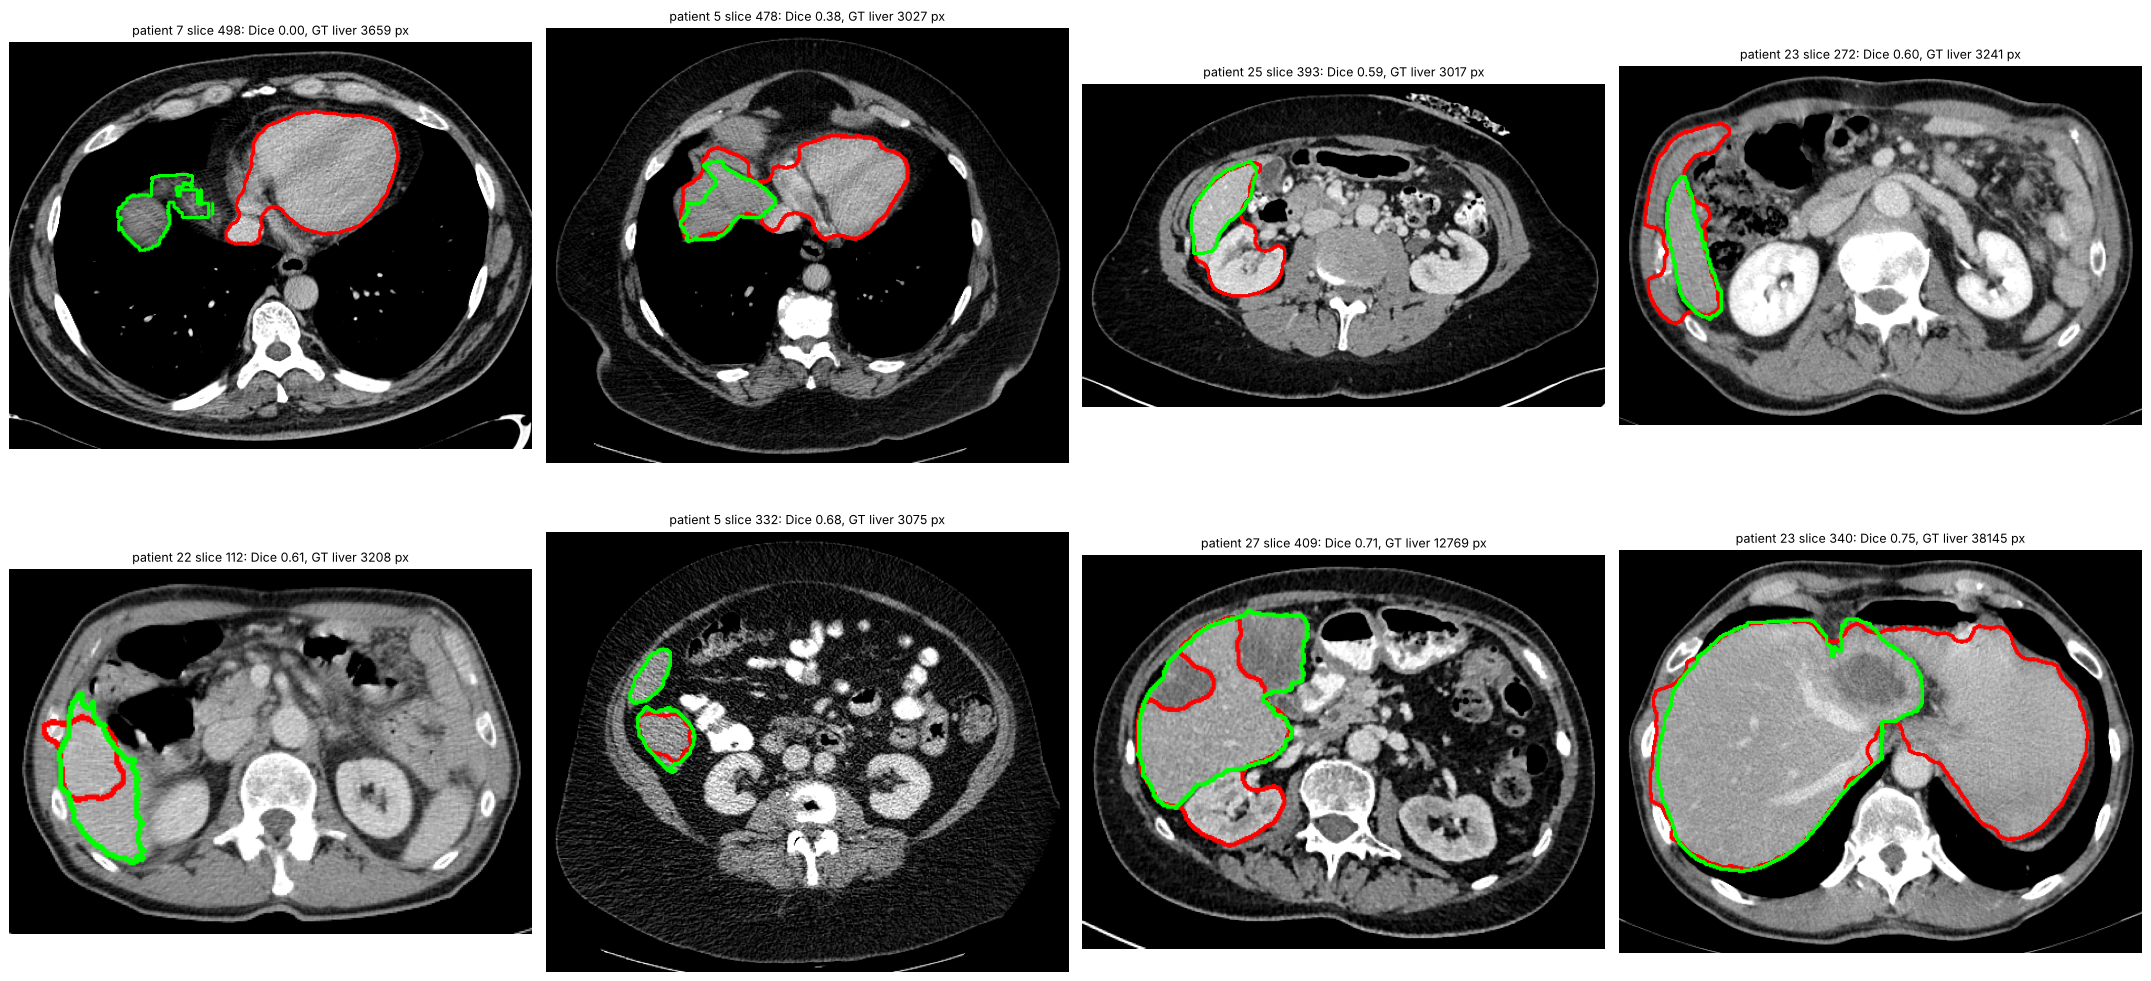

In [15]:
worst = res[(res.split == "test") & (res.strategy == "A")].sort_values("dice").head(8)
fig, ax = plt.subplots(2, 4, figsize=(24, 12))
for a, (_, row) in zip(ax.ravel(), worst.iterrows()):
    hu_p, m_p, ix = util.load_patient(DATA_DIR, int(row.patient)); k = list(ix).index(int(row.slice))
    hu_i, m_i = hu_p[k], m_p[k]
    o = S.segment_slice(hu_i, "A"); g0 = util.hu_to_gray(hu_i)
    a.imshow(crop_to_body(contour_overlay(g0, [(o["organ"], RED), (m_i >= 1, GREEN)], 2), o["body"])); a.axis("off")
    a.set_title("patient %d slice %d: Dice %.2f, GT liver %d px" % (row.patient, row.slice, row.dice, row.liver_px), fontsize=10)
fig.tight_layout(); fig.savefig(FIG_DIR + "/p2_failures_test.png", dpi=70); plt.show()

**Failure analysis (Strategy A).**

1. **Liver dome and liver tip (small liver, Dice drops).** Slices with fewer than 8000 liver pixels average a Dice of 0.76 (Strategy A) and 0.60 (Strategy B), against 0.94 (A) and 0.86 (B) for medium liver areas and 0.92 (A) and 0.87 (B) for large ones (table above). There, the liver is a small structure and several other organs are larger and closer to the expected position.
2. **Wrong organ selected near the heart** (patient 7 slice 498, Dice 0.00; patient 5 slice 478, Dice 0.38). The liver dome is small, while the heart has almost the same gray level, is larger and lies near the spatial prior, so the score *area x prior* picks the heart. The lesion detector then reports a lesion inside the heart (232 px, with no tumor in the slice). Strategy B placed its markers on the dome and reached 0.68 on the same slice.
3. **Leakage into organs of similar density** (patient 25 slice 393, patient 22 slice 112, patient 27 slice 409, patient 23 slices 272 and 340). Kidney, colon wall, stomach and spleen have HU values overlapping with the liver (LiTS portal-venous phase), and they touch the liver. An intensity-only method cannot separate them, and the opening (r = 5) is not enough to cut broad contact surfaces. In patient 23 slice 340 the mask even bridges to the large organ on the other side.
4. **Boundary errors where the liver contacts muscle and fat.** The red contours are generally smoother than the green ground truth and cut the lobulated fissure edges (patient 17 slice 422, patient 25 slice 522). This is the cost of the closing (r = 9) used to recover internal holes.
5. **Lesions.** Detection works when a lesion is clearly hypo-dense and compact (patient 17 slice 422: 112 predicted px against 116 ground-truth px), but lesions that are only slightly darker than the liver are missed (patient 23 slice 329: 637 px predicted in scattered pieces, against a 1613 px tumor), and small dark structures (vessels, the fissure) are over-detected (patient 25 slice 522: 411 px predicted against 76 px). Hence the false-alarm rate on tumor-free slices of 22 % (train) and 50 % (test, only 36 slices).

**Possible improvements (future work):** a shape/size prior or a registration-based atlas to reject the heart and kidney; a larger or oriented SE chosen from the local organ width; replacing the global intensity threshold for lesions with a local-contrast or texture-based detector; and processing a slice together with its neighbours (3D context).

## Summary of Phase 2

* **Strategy A (Multi-Otsu)** outperforms **Strategy B (marker-controlled watershed)**: liver Dice 0.897 vs 0.789 and IoU 0.833 vs 0.706 on the held-out test patients (training: 0.872 vs 0.792). A is better on 82 % of the test slices (paired Wilcoxon test, p = 5e-08). B wins in individual cases where Multi-Otsu selects the wrong class or organ (patient 5 slice 377).
* On medium and large liver sections the median Dice is above 0.94; the means are pulled down by small liver sections (dome and tip), where the spatial and intensity rules fail.
* **Lesion segmentation is the weak part:** mean Dice 0.27 (A, both sets), with 47 % (test) to 55 % (train) of the tumor slices overlapped by a detection, and many false alarms. This is the expected limit of a global intensity threshold on lesions that are often only a few HU darker than the liver.
* The masks of Strategy A (and the candidates of the lesion detector) are used in Phase 3.